In [69]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import auc

from tqdm.auto import tqdm
from sklearn.model_selection import KFold

In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [3]:
!wget $data -O homework-4.csv

--2026-10-18 11:58:30--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘homework-4.csv’

homework-4.csv      100%[===================>] 272.21K  --.-KB/s    in 0.004s  

2026-10-18 11:58:30 (65.6 MB/s) - ‘homework-4.csv’ saved [278746/278746]



In [4]:
df = pd.read_csv('homework-4.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [7]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']

In [8]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [9]:
df[numerical] = df[numerical].fillna(0.0)
df[categorical] = df[categorical].fillna('NA')

In [10]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [14]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [15]:
y_train = df_train.converted
y_full_train = df_full_train.converted
y_val = df_val.converted
y_test = df_test.converted

In [16]:
del df_train['converted']
#del df_full_train['converted']
del df_val['converted']
del df_test['converted']

## Question 1

In [17]:
from sklearn.metrics import roc_auc_score

In [26]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
for n in numerical:
    print(n, roc_auc_score(y_train, df_train[n]))

annual_income 0.6081977776250831
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
lead_score 0.7882254810906102


## Question 2

In [27]:
def train(df, y, C=1.0):
    dicts = df[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse= False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [30]:
dv, model = train(df_train, y_train)

In [32]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)

    y_pred = model.predict_proba(X)[:,1]

    return y_pred

In [33]:
y_pred = predict(df_val, dv, model)
y_pred

array([0.54472295, 0.79005191, 0.50977882, 0.52913934, 0.82072017,
       0.54245972, 0.50178712, 0.54698383, 0.82553291, 0.40583727,
       0.91301561, 0.33581811, 0.3078986 , 0.42704772, 0.62192275,
       0.53665458, 0.41931913, 0.84087339, 0.79969125, 0.61790114,
       0.61625177, 0.68059912, 0.85605897, 0.80784865, 0.62045997,
       0.45970701, 0.54556694, 0.41221371, 0.72714005, 0.46812072,
       0.77222173, 0.79043872, 0.61433884, 0.78549743, 0.49753403,
       0.66077266, 0.69804748, 0.7689654 , 0.65657485, 0.64127885,
       0.66509096, 0.57942799, 0.67830929, 0.61186087, 0.86890227,
       0.41469665, 0.84130122, 0.74229349, 0.68028533, 0.71891426,
       0.86417924, 0.64043347, 0.54246978, 0.70225148, 0.27894882,
       0.70826471, 0.62310687, 0.47781739, 0.37914002, 0.69936026,
       0.52032849, 0.69977687, 0.75148933, 0.58087478, 0.47001782,
       0.56863462, 0.91297177, 0.79972016, 0.82206537, 0.36140182,
       0.66132377, 0.52330037, 0.79295454, 0.72068061, 0.71234

In [36]:
roc_auc_score(y_val, y_pred)

0.7318222288173319

## Question 3

In [59]:
thresholds = np.linspace(0.0, 1.0, 101)  # step of 0.01

precisions = []
recalls = []
F1 = []

In [60]:
for t in thresholds:
    actual_positive = y_val == 1
    actual_negative = y_val == 0

    predict_positive = y_pred >= t
    predict_negative = y_pred < t

    tp = np.sum(predict_positive & actual_positive)
    fp = np.sum(predict_positive & actual_negative)
    fn = np.sum(predict_negative & actual_positive)

    # Calculate precision (handle division by zero if tp + fp == 0)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    # Calculate recall (handle division by zero if tp + fn == 0)
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 *((precision * recall)/(precision+ recall)) 

    precisions.append(precision)
    recalls.append(recall)
    F1.append(f1)

/tmp/ipykernel_2970/2801858819.py:16: RuntimeWarning: invalid value encountered in scalar divide
  f1 = 2 *((precision * recall)/(precision+ recall))


In [45]:
precisions = np.array(precisions)
recalls = np.array(recalls)

In [50]:
valid_mask = ~((precisions == 0) & (recalls == 0))

valid_thresholds = thresholds[valid_mask]
valid_precisions = precisions[valid_mask]
valid_recalls = recalls[valid_mask]
# Find the threshold with the smallest absolute difference
diffs = np.abs(valid_precisions - valid_recalls)
best_idx = np.argmin(diffs)
intersect_threshold = valid_thresholds[best_idx]

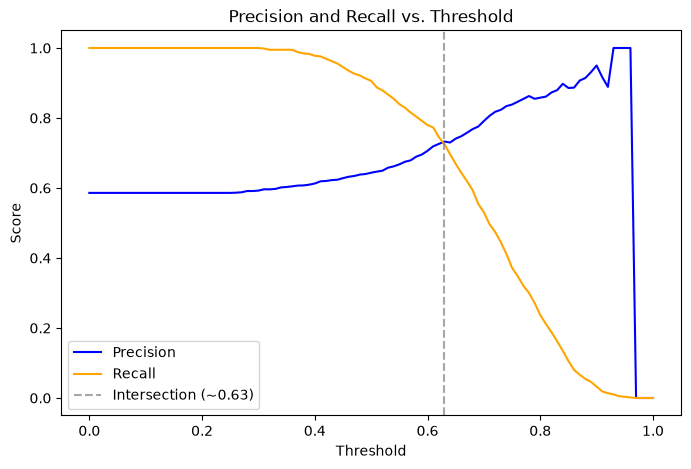

In [51]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label="Precision", color="blue")
plt.plot(thresholds, recalls, label="Recall", color="orange")
plt.axvline(
    x=intersect_threshold,
    color="grey",
    linestyle="--",
    alpha=0.7,
    label=f"Intersection (~{intersect_threshold:.2f})",
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs. Threshold")
plt.legend()

## Question 4

In [53]:
F1 = 2 *((precision * recall)/(precision+ recall))

/tmp/ipykernel_2970/636681219.py:1: RuntimeWarning: invalid value encountered in scalar divide
  F1 = 2 *((precision * recall)/(precision+ recall))


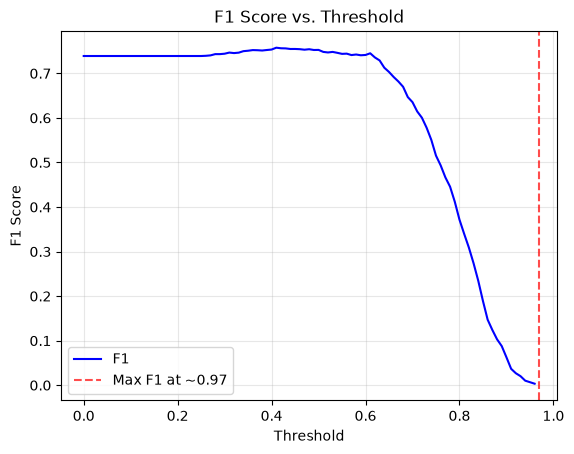

Maximal F1 score: nan
Optimal threshold: 0.97


In [67]:
f1_scores = np.array(F1)

# Find maximal F1 and the corresponding threshold
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
max_f1 = f1_scores[best_idx]
plt.plot(thresholds, f1_scores, label="F1", color="blue")
plt.axvline(
    x=best_threshold,
    color="red",
    linestyle="--",
    alpha=0.7,
    label=f"Max F1 at ~{best_threshold:.2f}",
)

plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("F1 Score vs. Threshold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Maximal F1 score: {max_f1:.4f}")
print(f"Optimal threshold: {best_threshold:.2f}")

## Question 5

In [76]:
kfold = KFold(n_splits =5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in tqdm(kfold.split(df_full_train), total=5):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]
    
    y_train = df_train.converted.values
    y_val = df_val.converted.values
    
    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)
    
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print(np.mean(scores), np.std(scores))

  0%|          | 0/5 [00:00<?, ?it/s]

0.7317269710972524 0.006853233151022138


## Question 6

In [79]:
def train(df, y, C=1.0):
    dicts = df[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse= False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [80]:
n_splits = 5

for C in [0.000001, 0.001, 1]:
    scores = []

    kfold = KFold(n_splits =n_splits, shuffle=True, random_state=1)

    for train_idx, val_idx in tqdm(kfold.split(df_full_train), total=n_splits):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.converted.values
        y_val = df_val.converted.values
    
        dv, model = train(df_train, y_train, C)
        y_pred = predict(df_val, dv, model)
    
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print(C, np.mean(scores), np.std(scores))

  0%|          | 0/5 [00:00<?, ?it/s]

1e-06 0.6167342250714795 0.018669799234831475


  0%|          | 0/5 [00:00<?, ?it/s]

0.001 0.7491721776030379 0.009996375455700753


  0%|          | 0/5 [00:00<?, ?it/s]

1 0.7317269710972524 0.006853233151022138
